In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from pathlib import Path
from hmmlearn import hmm                 # CategoricalHMM = HMM with discrete observations


# Ejercicio HMM 1: A mano (entender Forward y Viterbi)

Estados: 0 = Sano, 1 = Enfermo. Observaciones: 0 = Normal, 1 = Fiebre.

- π = [0.7, 0.3]
- A = [[0.8, 0.2],   (desde Sano)
       [0.4, 0.6]]   (desde Enfermo)
- B = [[0.9, 0.1],   (Sano: Normal, Fiebre)
       [0.3, 0.7]]   (Enfermo: Normal, Fiebre)

Secuencia observada: Fiebre, Fiebre

**a)** Calcula α₁ y α₂ para los dos estados y P(Fiebre, Fiebre).
**b)** Calcula δ₁ y δ₂ y di cuál es la secuencia de estados más probable.

In [17]:
#PI (estado inicial) #Sano = 0, enfermo = 1 
pi = np.array([0.7,0.3]) #Sano, enfermo

#Matriz de transicion (como cambia de un dia a otro)
A = np.array([[0.8,0.2], #Desde sano
                [0.4,0.6]]) #Desde enfermo

#Matriz de emision, (que ves en cada estado)
B  = np.array([[0.9, 0.1],         # Sano: Normal, Fiebre
               [0.3, 0.7]])        # Enfermo: Normal, Fiebre
#Observacion
o  = [0, 1, 1, 0, 1]                        # Fiebre, Fiebre

states = ["S", "E"]                 # hidden states


#“¿Probabilidad de la secuencia observada?” → Forward

def forward(pi, A, B, o):
    alpha = np.zeros((len(o), len(pi)))
    alpha[0] = pi * B[:, o[0]]                          # initialisation
    for t in range(1, len(o)):
        alpha[t] = B[:, o[t]] * (alpha[t - 1] @ A)      # recursion (vector form)
    return alpha

alpha = forward(pi, A, B, o)
p_obs = alpha[-1].sum()                                 # termination
#termination es la probabilidad de ver lo que viste los dos dias seguidos
print(alpha) 
#Fila 0 alpha 1 = Sano,Enfermo
#Fila 1 alpha 2 = Sano,Enfermo

#Cada numero de alpha dice: "haber visto todo hasta ese dia y estar en e se estado"
#dia 2, Enfermo > Sano, asique el ultimo dia lo mas probable es estar enfermo

#“¿Secuencia de estados más probable?” → Viterbi → Enfermo, Enfermo

def viterbi(pi, A, B, o):
    T, N = len(o), len(pi)
    delta = np.zeros((T, N))                  # scores la mejor puntuacion para llegar al camino
    psi = np.zeros((T, N), dtype=int)         # back-pointers de donde venia ese mejor camino

    delta[0] = pi * B[:, o[0]]                # initialisation: delta_1(j) = pi_j b_j(o_1)
    for t in range(1, T):
        # cand[i, j] = delta_{t-1}(i) * a_ij  (score of arriving to j from i)
        cand = delta[t - 1][:, None] * A
        psi[t] = cand.argmax(axis=0)          # best previous state for each j
        delta[t] = B[:, o[t]] * cand.max(axis=0)

    # termination: best final state, then follow psi backwards
    path = [int(delta[-1].argmax())]
    for t in range(T - 1, 0, -1):
        path.insert(0, int(psi[t, path[0]]))
    return path, delta[-1].max(), delta, psi

path, p_best, delta, psi = viterbi(pi, A, B, o)

# d) intermediate check
print("delta_1 =", np.round(delta[0], 5))
print("delta_2 =", np.round(delta[1], 5))
# by hand: delta_2(D) = b_D(VG) * max(delta_1(D)*0, delta_1(M)*0.5, delta_1(E)*0.5) = 0.1 * 0.0667*0.5
print("check delta_2(E):", 0.7 * max(0.07 * 0.2, 0.21 * 0.6))   # 0.0882
# e) the most probable sequence and its JOINT probability
print("\nViterbi path:", [states[s] for s in path])
print(f"max P(x,o) = {p_best:.4e}")

[[0.63       0.09      ]
 [0.054      0.126     ]
 [0.00936    0.06048   ]
 [0.028512   0.011448  ]
 [0.00273888 0.00879984]]
delta_1 = [0.63 0.09]
delta_2 = [0.0504 0.0882]
check delta_2(E): 0.0882

Viterbi path: ['S', 'E', 'E', 'E', 'E']
max P(x,o) = 2.8005e-03


Para comprobar a mano un valor, sigue estos pasos. Ejemplo: δ₂(Enfermo) = 0,0882.

1. Elige qué compruebas: día 2, estado Enfermo.

2. Busca en tus tablas los 3 tipos de dato:

Lo que ves hoy en Enfermo: B[Enfermo, Fiebre] = 0,7
Cómo se llega a Enfermo: A[Sano→Enfermo] = 0,2 y A[Enfermo→Enfermo] = 0,6
Lo de ayer: δ₁ = [0,07, 0,21] (tu delta_1)

3. Mételos en la fórmula: δ₂(E) = b × max(δ₁(S) × a_SE, δ₁(E) × a_EE)

print("check delta_2(E):", 0.7 * max(0.07 * 0.2, 0.21 * 0.6))   # 0.0882

Las cuentas: max(0,014 ; 0,126) = 0,126, y 0,7 × 0,126 = 0,0882

PARA EL CHECKEO A MANO
La pregunta del día 2: “Hoy estoy enfermo. ¿Cuál es la mejor forma de haber llegado hasta aquí?”

Solo hay 2 caminos para llegar a “enfermo hoy”:

🅰️ Ayer estaba sano y hoy me he puesto enfermo

¿Cómo de probable era estar sano ayer (con fiebre)? → 0,07 (esto lo calculamos el día 1)
¿Cómo de probable es pasar de sano a enfermo? → 0,2 (lo dice la tabla A)
Juntos: 0,07 × 0,2 = 0,014

🅱️ Ayer estaba enfermo y hoy sigo enfermo

¿Cómo de probable era estar enfermo ayer (con fiebre)? → 0,21 (del día 1)
¿Cómo de probable es seguir enfermo? → 0,6 (tabla A)
Juntos: 0,21 × 0,6 = 0,126

¿Cuál gana? 🅱️ (0,126 > 0,014). Lo más probable es que ya estuviera enfermo ayer.

Último paso: hoy también he visto fiebre. ¿Cómo de probable es tener fiebre estando enfermo? → 0,7 (tabla B).

# Ejercicio HMM 2: hmmlearn (el mismo modelo)

Usa el mismo HMM del Ejercicio 1:
- Estados: 0 = Sano, 1 = Enfermo
- Observaciones: 0 = Normal, 1 = Fiebre
- π = [0.7, 0.3]
- A = [[0.8, 0.2], [0.4, 0.6]]
- B = [[0.9, 0.1], [0.3, 0.7]]

**a)** Crea el modelo con `hmm.CategoricalHMM(n_components=2)` y asígnale `startprob_`, `transmat_` y `emissionprob_`.
**b)** Con `model.score()` calcula P(Fiebre, Fiebre) y comprueba que coincide con el Ejercicio 1. (Ojo: devuelve el logaritmo, usa `np.exp`.)
**c)** Con `model.decode(..., algorithm="viterbi")` obtén la secuencia de estados más probable y su probabilidad. Compáralas con las del Ejercicio 1.
**d)** Repite b) y c) con la secuencia Normal, Fiebre, Fiebre, Normal, Fiebre, y comprueba que tus funciones `forward` y `viterbi` dan lo mismo.

In [18]:
#2 estados ocultos, (Sano, Enfermo)
model = hmm.CategoricalHMM(n_components=2, init_params="", params="")   
model.n_features = 2                      # number of observation symbols
model.startprob_ = pi
model.transmat_ = A
model.emissionprob_ = B

X = np.array(o).reshape(-1, 1)                       # hmmlearn wants a COLUMN of integers, shape (T, 1)

#Viterbi con libreria
log_p_best, path = model.decode(X, algorithm="viterbi")
print("hmmlearn Viterbi:", [states[s] for s in path], f" P = {np.exp(log_p_best):.4e}")

# Most probable state at each t SEPARATELY (posterior / smoothing)
posterior = model.predict_proba(X)
print("Per-time maxima:", [states[s] for s in posterior.argmax(axis=1)])

#Forward
log_p = model.score(X)
print("P(o) =", np.exp(log_p))

hmmlearn Viterbi: ['S', 'E', 'E', 'E', 'E']  P = 2.8005e-03
Per-time maxima: ['S', 'E', 'E', 'S', 'E']
P(o) = 0.011538720000000008


Observado : N,F,F,N,F
P(o) = 0,0115: la probabilidad de ver esa secuencia de 5 días. Es más pequeña que antes porque hay más días y se multiplican más números.
Viterbi: S, E, E, E, E (P = 0,0028): el mejor camino completo.
Per-time: S, E, E, S, E: el estado más probable de cada día por separado

# Ejercicio HMM 3: Muestreo y gráfica

**a)** Genera 100 días con `model.sample(100, random_state=0)`.
**b)** Dibuja en una gráfica los estados ocultos y las observaciones generadas, y guárdala como `hmm_sample.png`.
**c)** Aplica Viterbi a las observaciones generadas y calcula el % de días en que acierta el estado real.

Primeros 10 estados: [0 0 0 0 1 1 1 0 0 0]
Primeras 10 obs:     [0 0 0 0 1 1 1 0 0 0]


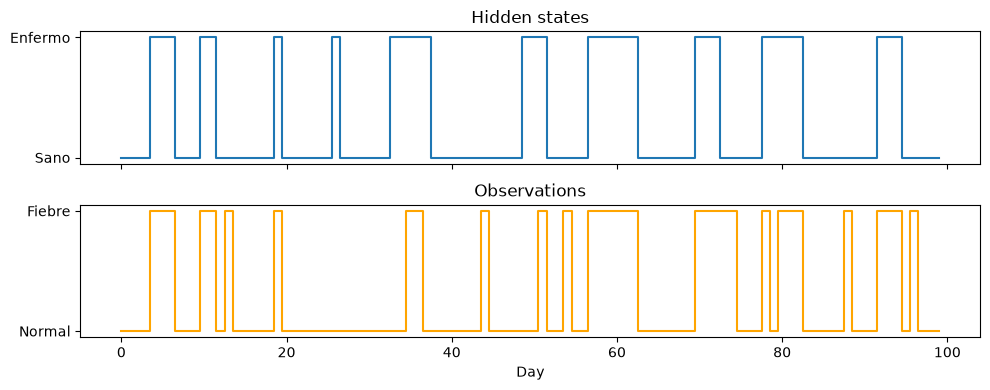

In [ ]:
X_sample, Z_sample = model.sample(100, random_state=0)
obs_sample = X_sample.ravel()      # observaciones: 0 = Normal, 1 = Fiebre
print("Primeros 10 estados:", Z_sample[:10])
print("Primeras 10 obs:    ", obs_sample[:10])

fig, ax = plt.subplots(2, 1, figsize=(10, 4), sharex=True)
ax[0].step(range(100), Z_sample, where="mid")
ax[0].set_yticks([0, 1], ["Sano", "Enfermo"])
ax[0].set_title("Hidden states")

ax[1].step(range(100), obs_sample, where="mid", color="orange")
ax[1].set_yticks([0, 1], ["Normal", "Fiebre"])
ax[1].set_title("Observations")
ax[1].set_xlabel("Day")


plt.tight_layout()
plt.savefig("hmm_sample.png", dpi=150)
plt.show()

In [22]:
# c) Viterbi sobre las observaciones generadas
log_p, path_sample = model.decode(X_sample, algorithm="viterbi")

aciertos = (path_sample == Z_sample)        # True si Viterbi acierta ese día
accuracy = aciertos.mean() * 100            # True = 1, False = 0 → media = % de aciertos

print(f"Viterbi acierta el {accuracy:.1f}% de los días")
print("Días acertados:", aciertos.sum(), "de", len(Z_sample))

ax[0].step(range(100), path_sample, where="mid", linestyle="--", label="Viterbi")
ax[0].legend()

Viterbi acierta el 86.0% de los días
Días acertados: 86 de 100


La idea: Viterbi elige en cada paso el máximo. Si dos opciones dan exactamente el mismo número, hay empate, y el código tiene que elegir una. np.argmax siempre se queda con la primera (el índice más bajo). Por eso dos personas (o dos librerías) pueden sacar caminos distintos y los dos ser correctos.


**Ties in Viterbi.** If two candidate paths have exactly the same probability at a step,
the maximum is not unique. `np.argmax` always returns the first index (lowest state number),
so the result depends on how the tie is broken. Another implementation may return a
different path with the same probability; both are valid most probable paths.
To check it, compare the probabilities (`delta`), not only the paths.